# Setup and Load the Dataset

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Load dataset
digits = load_digits()

X = digits.images
y = digits.target

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of classes:", len(np.unique(y)))

Dataset shape: (1797, 8, 8)
Labels shape: (1797,)
Number of classes: 10


# Prepare the Data as Sequence

In [2]:
# Normalize pixel values
X = X.astype(np.float32) / 16.0

# Convert each 8x8 image into a sequence:
# 8 time steps, with 8 features at each step
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

print("Sequence shape:", X.shape)
print("Label shape:", y.shape)

Sequence shape: torch.Size([1797, 8, 8])
Label shape: torch.Size([1797])


# Train/ Test Split

In [3]:
# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training samples: 1437
Testing samples: 360
Training shape: torch.Size([1437, 8, 8])
Testing shape: torch.Size([360, 8, 8])


# Create PyTorch Datasets and Data Loaders

In [4]:
from torch.utils.data import TensorDataset, DataLoader

# Create PyTorch datasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 23
Testing batches: 6


# Define the RNN Model

In [5]:
class RNNClassifier(nn.Module):
    def __init__(self, input_size=8, hidden_size=64, num_classes=10):
        super(RNNClassifier, self).__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, hidden = self.rnn(x)

        # Use the output from the final time step
        final_output = output[:, -1, :]

        return self.fc(final_output)


# Create the RNN model
rnn_model = RNNClassifier()

print(rnn_model)

RNNClassifier(
  (rnn): RNN(8, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=10, bias=True)
)


# Setup Training

In [6]:
# Loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    rnn_model.parameters(),
    lr=0.001
)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001


# Train the RNN

In [7]:
num_epochs = 15
train_losses = []

for epoch in range(num_epochs):
    rnn_model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = rnn_model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

Epoch [1/15], Loss: 2.2384
Epoch [2/15], Loss: 1.8383
Epoch [3/15], Loss: 1.3510
Epoch [4/15], Loss: 1.1290
Epoch [5/15], Loss: 0.9605
Epoch [6/15], Loss: 0.8439
Epoch [7/15], Loss: 0.7633
Epoch [8/15], Loss: 0.6941
Epoch [9/15], Loss: 0.6379
Epoch [10/15], Loss: 0.5614
Epoch [11/15], Loss: 0.5132
Epoch [12/15], Loss: 0.4613
Epoch [13/15], Loss: 0.4276
Epoch [14/15], Loss: 0.3783
Epoch [15/15], Loss: 0.3468


# Plot the RNN Training Loss

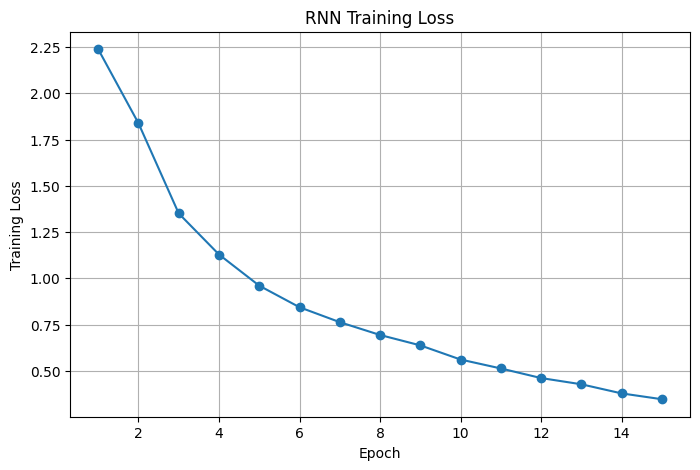

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("RNN Training Loss")
plt.grid(True)

plt.show()

# Evaluate the RNN on the Test Set

In [9]:
rnn_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = rnn_model(X_batch)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(y_batch.numpy())

rnn_accuracy = accuracy_score(all_labels, all_predictions)

print(f"RNN Test Accuracy: {rnn_accuracy * 100:.2f}%")

RNN Test Accuracy: 88.89%


# Evaluate the RNN in More Detail

In [10]:
from sklearn.metrics import classification_report, confusion_matrix

print("RNN Classification Report:\n")
print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)

print("RNN Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

RNN Classification Report:

              precision    recall  f1-score   support

           0     1.0000    0.9444    0.9714        36
           1     0.6739    0.8611    0.7561        36
           2     1.0000    1.0000    1.0000        35
           3     0.8409    1.0000    0.9136        37
           4     0.8780    1.0000    0.9351        36
           5     0.9167    0.8919    0.9041        37
           6     0.9429    0.9167    0.9296        36
           7     0.9706    0.9167    0.9429        36
           8     0.8400    0.6000    0.7000        35
           9     0.9000    0.7500    0.8182        36

    accuracy                         0.8889       360
   macro avg     0.8963    0.8881    0.8871       360
weighted avg     0.8961    0.8889    0.8874       360

RNN Confusion Matrix:
[[34  0  0  0  1  0  1  0  0  0]
 [ 0 31  0  1  0  0  1  0  0  3]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  1  0  1  1 33  0  0 

# Define the LSTM Model

In [11]:
class LSTMClassifier(nn.Module):
    def __init__(self, input_size=8, hidden_size=64, num_classes=10):
        super(LSTMClassifier, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)

        # Use the output from the final time step
        final_output = output[:, -1, :]

        return self.fc(final_output)


# Create the LSTM model
lstm_model = LSTMClassifier()

print(lstm_model)

LSTMClassifier(
  (lstm): LSTM(8, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=10, bias=True)
)


# Setup the LSTM Optimizer

In [12]:
# Loss function and optimizer for LSTM
lstm_criterion = nn.CrossEntropyLoss()

lstm_optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001


# Train the LSTM

In [13]:
num_epochs = 15
lstm_train_losses = []

for epoch in range(num_epochs):
    lstm_model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        lstm_optimizer.zero_grad()

        outputs = lstm_model(X_batch)
        loss = lstm_criterion(outputs, y_batch)

        loss.backward()
        lstm_optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    lstm_train_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

Epoch [1/15], Loss: 2.2954
Epoch [2/15], Loss: 2.2462
Epoch [3/15], Loss: 1.9441
Epoch [4/15], Loss: 1.4934
Epoch [5/15], Loss: 1.2063
Epoch [6/15], Loss: 0.9926
Epoch [7/15], Loss: 0.8535
Epoch [8/15], Loss: 0.7319
Epoch [9/15], Loss: 0.6429
Epoch [10/15], Loss: 0.5899
Epoch [11/15], Loss: 0.5502
Epoch [12/15], Loss: 0.4817
Epoch [13/15], Loss: 0.4817
Epoch [14/15], Loss: 0.4418
Epoch [15/15], Loss: 0.3971


# Plot LSTM Training Loss

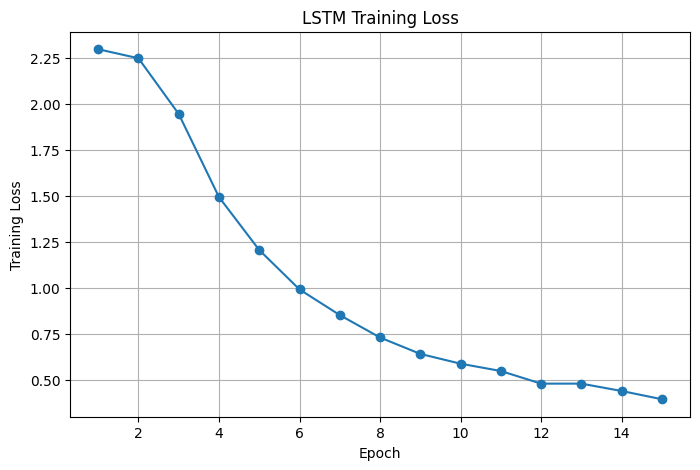

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    lstm_train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("LSTM Training Loss")
plt.grid(True)

plt.show()

# Evaluate the LSTM on the Test Set

In [15]:
lstm_model.eval()

lstm_predictions = []
lstm_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = lstm_model(X_batch)
        predictions = torch.argmax(outputs, dim=1)

        lstm_predictions.extend(predictions.numpy())
        lstm_labels.extend(y_batch.numpy())

lstm_accuracy = accuracy_score(lstm_labels, lstm_predictions)

print(f"LSTM Test Accuracy: {lstm_accuracy * 100:.2f}%")

LSTM Test Accuracy: 85.56%


# LSTM Classification Report and Confusion Matrix

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

print("LSTM Classification Report:\n")

print(
    classification_report(
        lstm_labels,
        lstm_predictions,
        digits=4
    )
)

print("LSTM Confusion Matrix:")
print(confusion_matrix(lstm_labels, lstm_predictions))

LSTM Classification Report:

              precision    recall  f1-score   support

           0     1.0000    0.9444    0.9714        36
           1     0.6667    0.8333    0.7407        36
           2     0.8889    0.9143    0.9014        35
           3     0.9444    0.9189    0.9315        37
           4     0.9459    0.9722    0.9589        36
           5     0.8500    0.9189    0.8831        37
           6     0.9429    0.9167    0.9296        36
           7     0.7941    0.7500    0.7714        36
           8     0.6667    0.6286    0.6471        35
           9     0.9000    0.7500    0.8182        36

    accuracy                         0.8556       360
   macro avg     0.8600    0.8547    0.8553       360
weighted avg     0.8606    0.8556    0.8561       360

LSTM Confusion Matrix:
[[34  0  0  0  1  0  1  0  0  0]
 [ 0 30  0  0  0  1  0  3  0  2]
 [ 0  2 32  0  0  0  0  0  0  1]
 [ 0  0  1 34  0  0  0  2  0  0]
 [ 0  0  0  0 35  0  1  0  0  0]
 [ 0  0  0  0  1 34  0  

# Create the Final Comparison Table

In [17]:
import pandas as pd

comparison_results = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "RNN",
        "LSTM",
        "Target"
    ],
    "Test Accuracy": [
        "10.00%",
        "88.89%",
        "85.56%",
        "93.00%"
    ],
    "Macro Precision": [
        "-",
        "89.63%",
        "86.00%",
        "-"
    ],
    "Macro Recall": [
        "-",
        "88.81%",
        "85.47%",
        "-"
    ],
    "Macro F1-Score": [
        "-",
        "88.71%",
        "85.53%",
        "-"
    ]
})

display(comparison_results)

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Majority Baseline,10.00%,-,-,-
1,RNN,88.89%,89.63%,88.81%,88.71%
2,LSTM,85.56%,86.00%,85.47%,85.53%
3,Target,93.00%,-,-,-


# Create the Final Accuracy Comparison Plot

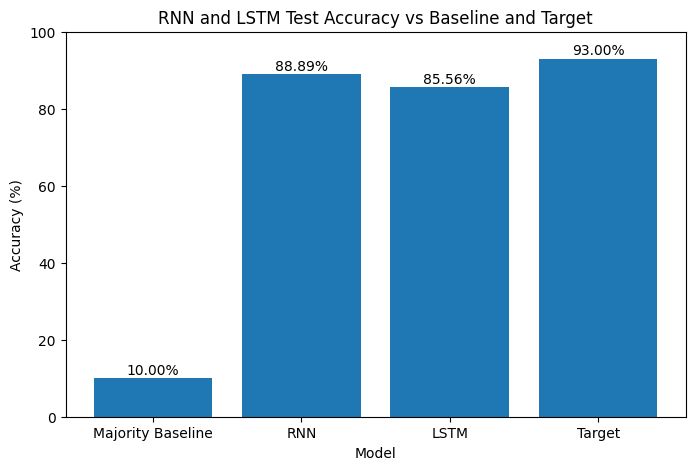

In [18]:
models = ["Majority Baseline", "RNN", "LSTM", "Target"]
accuracies = [10.00, 88.89, 85.56, 93.00]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("RNN and LSTM Test Accuracy vs Baseline and Target")
plt.ylim(0, 100)

# Add accuracy values above each bar
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()

<Figure size 700x600 with 0 Axes>

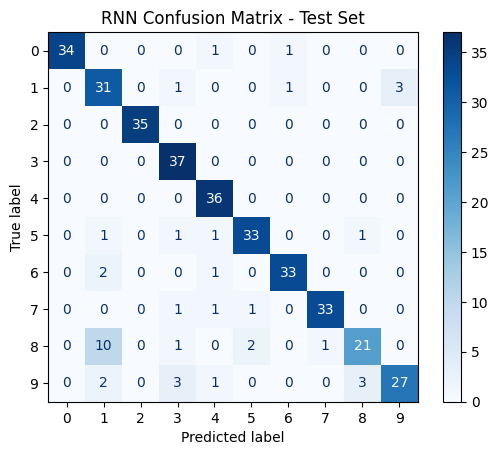

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

disp.plot(cmap="Blues", values_format="d")

plt.title("RNN Confusion Matrix - Test Set")
plt.show()